In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

The song_recomendation_B.csv dataset is used as the primary data set, containing information about songs, artists, genres, and audio features. This dataset serves as the basis for analysis, data exploration, and the development of a song recommendation system.

In [2]:
df = pd.read_csv("song_recomendation_B.csv")
df.head()

,Track URI,Track Name,Artist Name(s),Album Name,Album Release Date,Popularity,Artist Genres,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,spotify:track:6a8GbQIlV8HBUW3c6Uk9PH,I Know You Want Me (Calle Ocho),Pitbull,Pitbull Starring In Rebelution,2009-10-23,64,"dance pop,miami hip hop,pop",0.825,0.743,2.0,-5.995,1.0,0.1490,0.0142,0.000021,0.2370,0.800,127.045,4.0
1,spotify:track:70XtWbcVZcpaOddJftMcVi,From the Bottom of My Broken Heart,Britney Spears,...Baby One More Time (Digital Deluxe Version),1999-01-12,56,"dance pop,pop",0.677,0.665,7.0,-5.171,1.0,0.0305,0.5600,NaN,0.3380,0.706,74.981,4.0
2,spotify:track:72WZtWs6V7uu3aMgMmEkYe,You Can't Always Get What You Want,The Rolling Stones,Let It Bleed,1969-12-05,0,"album rock,british invasion,classic rock,rock",0.319,0.627,0.0,-9.611,1.0,0.0687,0.6750,0.000073,0.2890,0.497,85.818,4.0
3,spotify:track:4bEb3KE4mSKlTFjtWJQBqO,Don't Stop - 2004 Remaster,Fleetwood Mac,Rumours,1977-02-04,79,"album rock,classic rock,rock,soft rock,yacht rock",0.671,0.710,9.0,-7.724,1.0,0.0356,0.0393,0.000011,0.0387,0.834,118.745,4.0
4,spotify:track:0d2iYfpKoM0QCKvcLCkBao,Eastside (with Halsey & Khalid),"benny blanco, Halsey, Khalid",Eastside (with Halsey & Khalid),2018-07-12,78,"pop,electropop,etherpop,indie poptimism,pop,po...",0.560,0.680,6.0,-7.648,0.0,0.3210,0.5550,0.000000,0.1160,0.319,89.391,4.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           4999 non-null   object 
 1   Track Name          4999 non-null   object 
 2   Artist Name(s)      4999 non-null   object 
 3   Album Name          4999 non-null   object 
 4   Album Release Date  4997 non-null   object 
 5   Popularity          4999 non-null   int64  
 6   Artist Genres       4744 non-null   object 
 7   Danceability        4747 non-null   float64
 8   Energy              4997 non-null   float64
 9   Key                 4997 non-null   float64
 10  Loudness            4997 non-null   float64
 11  Mode                4997 non-null   float64
 12  Speechiness         4997 non-null   float64
 13  Acousticness        4997 non-null   float64
 14  Instrumentalness    4897 non-null   float64
 15  Liveness            4997 non-null   float64
 16  Valenc

In [4]:
print("Before preprocessing")
df.isnull().sum()

Before preprocessing


Track URI               0
Track Name              0
Artist Name(s)          0
Album Name              0
Album Release Date      2
Popularity              0
Artist Genres         255
Danceability          252
Energy                  2
Key                     2
Loudness                2
Mode                    2
Speechiness             2
Acousticness            2
Instrumentalness      102
Liveness                2
Valence                 2
Tempo                   2
Time Signature          2
dtype: int64

Based on the results of the missing values ​​check, most variables in the dataset do not have blank values. However, several columns contain missing values, particularly in Artist Genres, Danceability, and Instrumentalness, each of which has a significant number of blank values. Furthermore, several numeric features such as Energy, Loudness, Tempo, and Album Release Date also have a small amount of missing data. Therefore, a data preprocessing stage is required to handle blank values ​​so that analysis and modeling can be carried out optimally.

In [5]:
df['Artist Genres'].fillna('Unknown', inplace=True)
df['Album Release Date'] = pd.to_datetime(df['Album Release Date'], errors='coerce')
median_date = df['Album Release Date'].median()
df['Album Release Date'].fillna(median_date, inplace=True)
numeric_cols = ['Danceability','Energy','Key','Loudness','Mode','Speechiness',
                'Acousticness','Instrumentalness','Liveness','Valence','Tempo','Time Signature']
for col in numeric_cols:
    df[col].fillna(df[col].median(), inplace=True)

C:\Users\olive\AppData\Local\Temp\ipykernel_5288\2106964111.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Artist Genres'].fillna('Unknown', inplace=True)
C:\Users\olive\AppData\Local\Temp\ipykernel_5288\2106964111.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For ex

Empty values ​​in categorical data are filled with “Unknown”, while empty values ​​in numeric data and album release dates are filled using the median to maintain the stability of data distribution.

In [6]:
print("After preprocessing")
df.isnull().sum()

After preprocessing


Track URI             0
Track Name            0
Artist Name(s)        0
Album Name            0
Album Release Date    0
Popularity            0
Artist Genres         0
Danceability          0
Energy                0
Key                   0
Loudness              0
Mode                  0
Speechiness           0
Acousticness          0
Instrumentalness      0
Liveness              0
Valence               0
Tempo                 0
Time Signature        0
dtype: int64

In [7]:
df.describe()

,Album Release Date,Popularity,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
count,4999,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000,4999.000000
mean,2004-11-02 09:24:01.008201728,38.062813,0.608386,0.682588,5.145629,-7.250286,0.694139,0.065296,0.209183,0.026915,0.185146,0.582879,121.731209,3.961192
min,1958-01-01 00:00:00,0.000000,0.000000,0.000020,0.000000,-29.368000,0.000000,0.000000,0.000009,0.000000,0.018500,0.000000,0.000000,0.000000
25%,1999-11-10 00:00:00,0.000000,0.524000,0.557000,2.000000,-9.046000,0.000000,0.032900,0.018250,0.000000,0.089200,0.396000,103.006500,4.000000
50%,2008-12-02 00:00:00,43.000000,0.616000,0.714000,5.000000,-6.554000,1.000000,0.042700,0.092900,0.000006,0.128000,0.594000,120.853000,4.000000
75%,2014-01-01 00:00:00,64.000000,0.703000,0.833500,8.000000,-4.868000,1.000000,0.066800,0.323000,0.000449,0.244500,0.778000,134.785500,4.000000
max,2023-06-30 00:00:00,98.000000,0.984000,0.997000,11.000000,-0.276000,1.000000,0.711000,0.987000,0.973000,0.982000,0.991000,213.654000,5.000000
std,NaN,29.501712,0.141414,0.191294,3.565934,3.241412,0.460817,0.062480,0.249819,0.117725,0.147831,0.238736,26.239209,0.262530


**Exploratoy Data Analysis**

In [8]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include='object').columns

**Correlation Heatmap of Numerical Features**

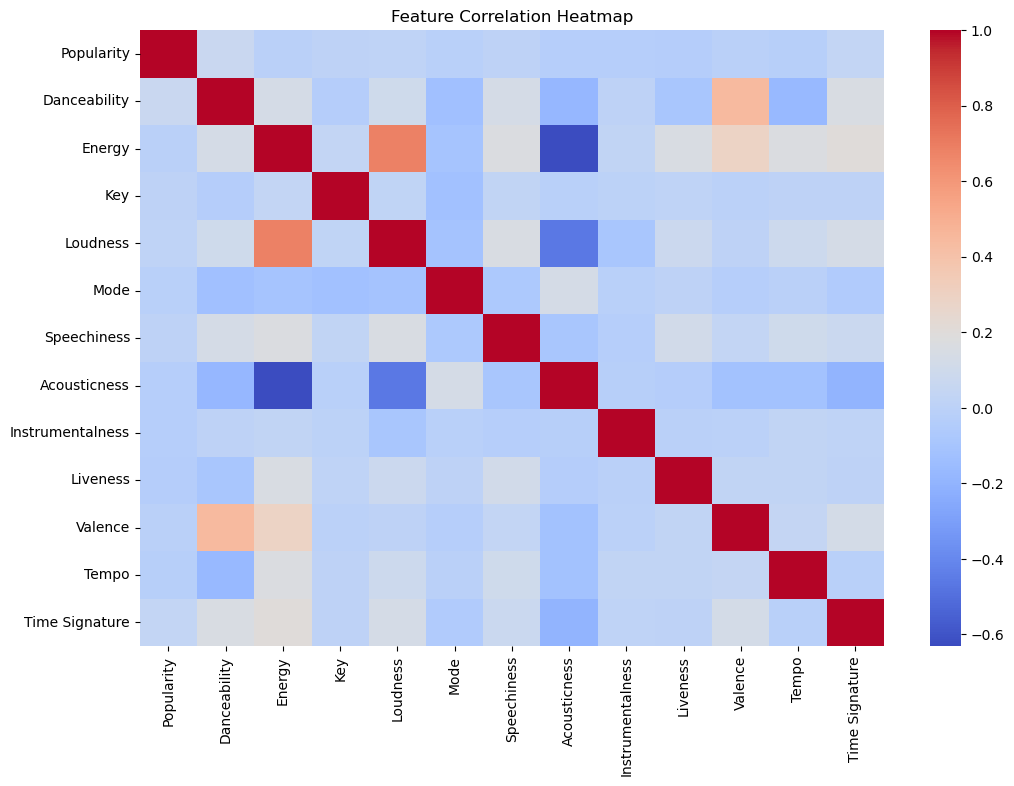

In [9]:
plt.figure(figsize=(12,8))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

This heatmap shows the relationships between music features such as Danceability, Energy, and Valence. Some features, such as Loudness and Energy, have a strong positive correlation, indicating a connection in audio characteristics. This pattern is useful for music analysis and recommendation system development. This insight helps select relevant features for genre modeling or classification.


**Boxplot of Numerical Variable**

Text(0.5, 1.0, 'Boxplot of All Numerical Variables')

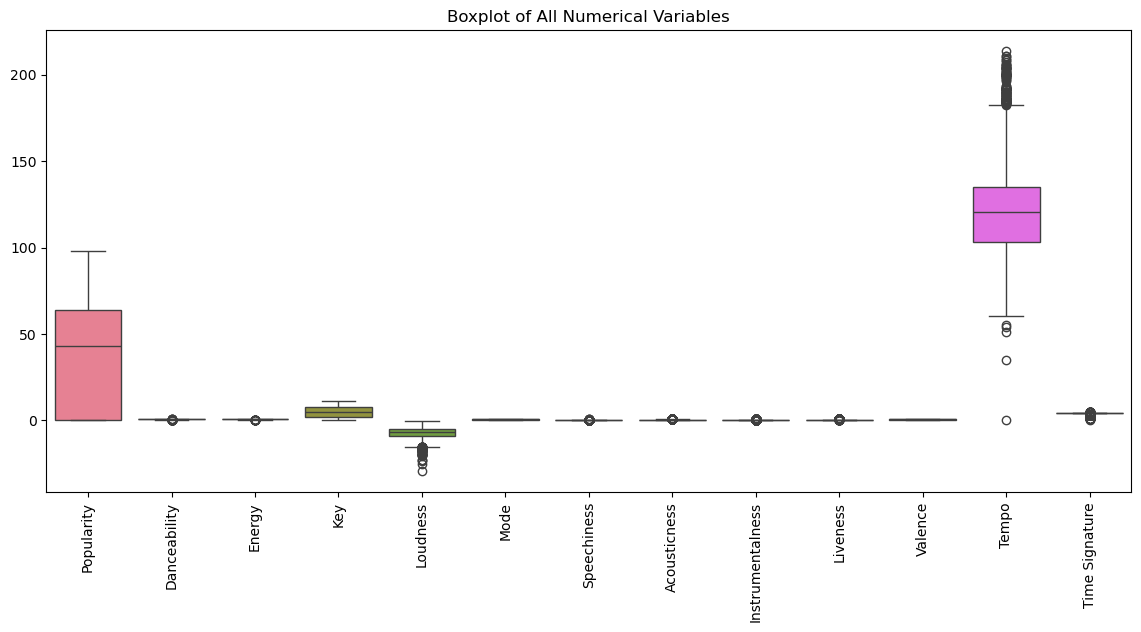

In [10]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df[num_cols])
plt.xticks(rotation=90)
plt.title("Boxplot of All Numerical Variables")

This boxplot shows the distribution of music features such as Popularity, Tempo, and Valence. Some features, such as Popularity, have wide ranges and outliers, while features like Mode and Time Signature are more stable. This pattern helps understand variability between features and is important for attribute selection in music analysis. This insight is useful for data exploration and predictive model development.

In [11]:
df_clean = df.copy()

num_cols_clean = [
    'Popularity',
    'Tempo',
    'Loudness',
]

for col in num_cols_clean:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]


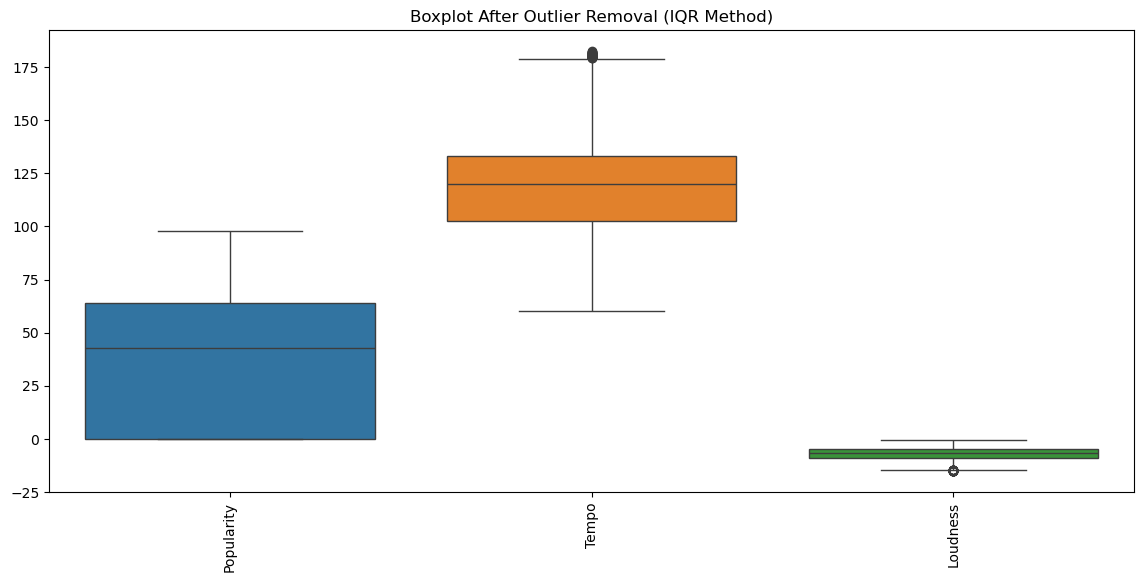

In [12]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df_clean[num_cols_clean])
plt.xticks(rotation=90)
plt.title("Boxplot After Outlier Removal (IQR Method)")
plt.show()

This boxplot displays the distribution of Popularity, Tempo, and Loudness after outliers were removed using the IQR method. The data range is more representative, with a clearly visible median and a more stable distribution. Some outliers still appear, but they no longer dominate the scale. This visualization is important to ensure that statistical analysis is accurate and unbiased by extreme values.

**Distribution of song popularity**

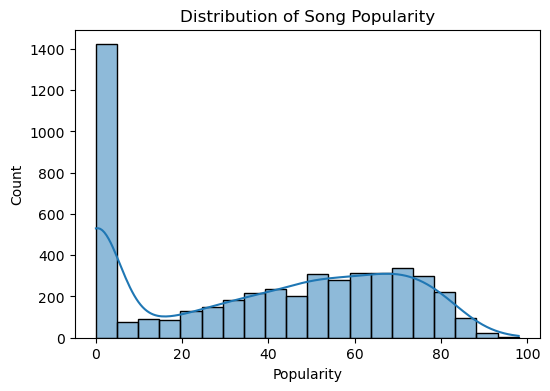

In [13]:
plt.figure(figsize=(6,4))
sns.histplot(df['Popularity'], bins=20, kde=True)
plt.title('Distribution of Song Popularity')
plt.show()

This histplot shows a bimodal distribution of song popularity: many songs are very unpopular, while others are quite popular, in the 60–70 range. This pattern indicates the presence of two dominant groups lesser known songs and songs with a good market acceptance. This insight is useful for analyzing music trends and developing more targeted promotional strategies.


**Scatter Plot of Energy and Danceability**

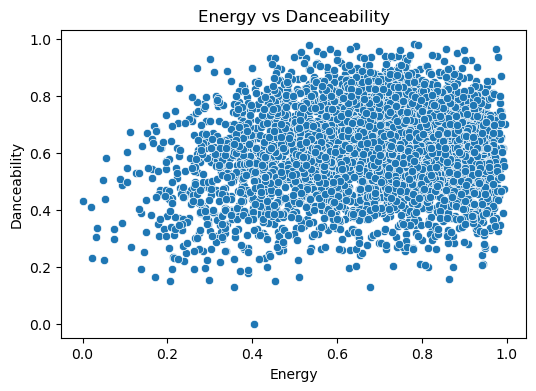

In [14]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='Energy', y='Danceability', data=df)
plt.title('Energy vs Danceability')
plt.show()

This scatterplot shows a positive correlation between Energy and Danceability, with data concentration in the range of 0.4–0.9. This means that energetic songs tend to be easier to dance to. This pattern is useful for analyzing music preferences and developing audio-feature-based recommendation systems.

**Distribution of Top 10 Artist Genres**

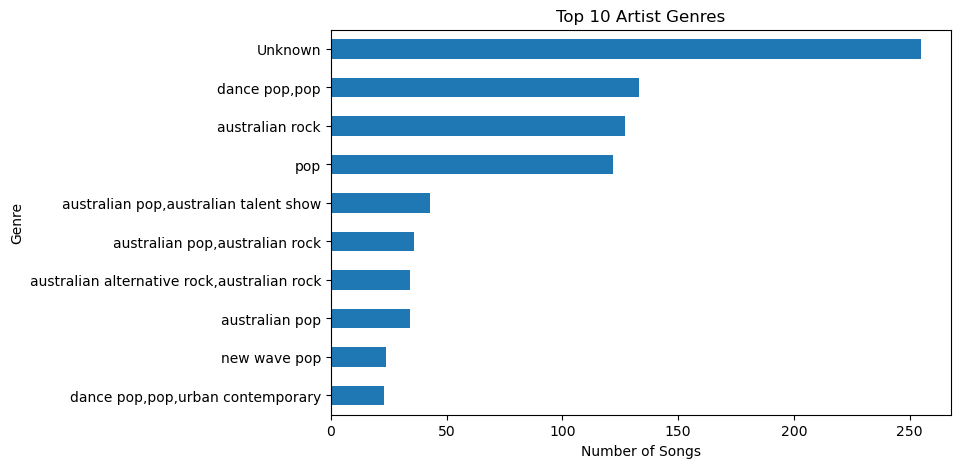

In [15]:
plt.figure(figsize=(8,5))
df['Artist Genres'].value_counts().head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Artist Genres')
plt.xlabel('Number of Songs')
plt.ylabel('Genre')
plt.show()

This bar chart shows the top 10 music genres by number of songs, with the Unknown category being the most dominant. Genres like dance pop and pop also appear strongly, while other genres are more specific and fewer in number. This pattern reflects the dominance of popular genres and the presence of unclassified data. This insight is useful for analyzing genre trends and evaluating the quality of music metadata.

**Recomendation System**

In [16]:
df_clean['Track Name Clean'] = (
    df_clean['Track Name']
    .str.lower()
    .str.replace('[^a-z0-9 ]', '', regex=True)
)

At this stage, the Track Name column is reprocessed by creating a new feature called Track Name Clean. This process involves converting the text to lowercase and removing non-alphanumeric characters such as punctuation and symbols. The purpose of this text cleanup is to standardize the format of song titles, making the search and matching process in the recommendation system more accurate and less sensitive to spelling differences.

In [17]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=500
)

tfidf_matrix = tfidf.fit_transform(df_clean['Artist Genres'])
similarity_matrix = cosine_similarity(tfidf_matrix)

def recommend_song(track_name, df=df_clean, similarity_matrix=similarity_matrix, top_n=5):
    track_name = track_name.lower()
    track_name = ''.join(c for c in track_name if c.isalnum() or c == ' ')

    matches = df[df['Track Name Clean'].str.contains(track_name, na=False)]

    if matches.empty:
        return "Song not found in dataset"

    idx = matches.index[0]

    sim_scores = list(enumerate(similarity_matrix[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    sim_scores = sim_scores[1:top_n+1]
    song_indices = [i[0] for i in sim_scores]

    return df.loc[song_indices, ['Track Name', 'Artist Name(s)', 'Artist Genres']]

recommend_song("mercy")
recommend_song("eastside")
recommend_song("dont stop")

,Track Name,Artist Name(s),Artist Genres
561,That's Rock 'N' Roll,Shaun Cassidy,bubblegum pop
2713,Fallin' For You,Colbie Caillat,"dance pop,neo mellow,pop"
1232,7 rings,Ariana Grande,pop
1965,Kids,OneRepublic,"piano rock,pop"
3369,Cherry Lips (Go Baby Go),Garbage,"alternative rock,dance rock,electronic rock,pe..."


In the recommendation system development stage, the Artist Genres feature is represented using the TF-IDF method to convert genre information into a numeric vector. This representation allows the system to understand the level of similarity between songs based on their musical characteristics. Furthermore, cosine similarity is used to measure the level of similarity between songs. When a user enters a song title, the system searches the dataset for that song and recommends five other songs with the highest similarity scores, ensuring musically relevant recommendations.
